### 1. Import Libraries 

In [1]:
# Data manipulation 
import pandas as pd 
import numpy as np 

# Data visualization 
import matplotlib.pyplot as plt 
import seaborn as sns 

# Display settings 
pd.set_option("display.max_columns", None)

# Plot style
sns.set_style("whitegrid")

### 2. Load Data 

In [2]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")

### 3. Inspect Datasets 

In [3]:
# Orders dataset 
print("Orders dataset")
print(orders.head())
print("\n")
orders.info()

print("\n")

# Reviews dataset
print("Reviews dataset")
print(reviews.head())
print("\n")
print(reviews.info())

print("\n")

# Order item dataset 
print("Order item dataset")
print(order_items.head())
print("\n")
print(order_items.info())

Orders dataset
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00   

### 4. Clean Dataset

In [4]:
## Orders Dataset

# Convert columns to datetime 
date_columns = [ 
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns: 
    orders[col] = pd.to_datetime(orders[col])

# Keep delivered orders 
orders = orders[
    orders["order_status"] == "delivered"
]

# Remove missing delivery dates
orders = orders[
    orders["order_delivered_customer_date"].notnull()
]

# Remove inconsistent records 
orders = orders[
    orders["order_delivered_customer_date"] >=
    orders["order_purchase_timestamp"]
]


## Review Dataset 

# Remove missing review scores
reviews = reviews[ 
    reviews["review_score"].notnull()
]

### 5. Prepare Order Items Dataset 

In [5]:
# Group items by order 
order_items_grouped = order_items.groupby("order_id").agg({
    "price" : "sum",
    "freight_value" : "sum",
    "order_item_id" : "count"
}).reset_index()

# Rename columns 
order_items_grouped.columns = [
    "order_id",
    "total_order_value",
    "total_freight_value",
    "item_count"
]

# Verify dataset 
print(order_items_grouped.head())

                           order_id  total_order_value  total_freight_value  \
0  00010242fe8c5a6d1ba2dd792cb16214              58.90                13.29   
1  00018f77f2f0320c557190d7a144bdd3             239.90                19.93   
2  000229ec398224ef6ca0657da4fc703e             199.00                17.87   
3  00024acbcdf0a6daa1e931b038114c75              12.99                12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9             199.90                18.14   

   item_count  
0           1  
1           1  
2           1  
3           1  
4           1  


### 6. Merge Datasets 

In [6]:
# Merge orders and reviews 
df = orders.merge(
    reviews, 
    on="order_id",
    how="inner"
)

# Merge order items dataset 
df = df.merge(
    order_items_grouped, 
    on="order_id",
    how="inner"
)

# Verify merged dataset 
print(df.head())

print("\nDataset Shape:")
print(df.shape)

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08

### 7. Create New Variables 

In [7]:
# Delivery time 
df["delivery_time"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days

# Delivery delay 
df["delivery_delay"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days

# Delayed orders 
df["is_delayed"] = np.where(df["delivery_delay"] > 0, 1, 0)

# Poor customer experience 
df["poor_experience"] = np.where(df["review_score"] <= 2, 1, 0)



### 8. Verify New Variables 

In [8]:
# Verify new variables 
print(df[[
    "delivery_time",
    "delivery_delay",
    "is_delayed",
    "poor_experience", 
]].head())

   delivery_time  delivery_delay  is_delayed  poor_experience
0              8              -8           0                0
1             13              -6           0                0
2              9             -18           0                0
3             13             -13           0                0
4              2             -10           0                0


In [9]:
# Summary statistics 
print(df[[
    "delivery_time",
    "delivery_delay",
    "total_freight_value",
    "item_count"
    ]].describe())

       delivery_time  delivery_delay  total_freight_value    item_count
count   96353.000000    96353.000000         96353.000000  96353.000000
mean       12.058472      -11.916806            22.757810      1.141687
std         9.462698       10.112261            21.496018      0.535362
min         0.000000     -147.000000             0.000000      1.000000
25%         6.000000      -17.000000            13.840000      1.000000
50%        10.000000      -12.000000            17.160000      1.000000
75%        15.000000       -7.000000            23.990000      1.000000
max       208.000000      188.000000          1794.960000     21.000000


In [10]:
# On average, orders were delivered about 12 days earlier then the estimated delivery date 

In [11]:
# Max delivery time 
df[df["delivery_time"] == df["delivery_time"].max()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,total_order_value,total_freight_value,item_count,delivery_time,delivery_delay,is_delayed,poor_experience
53879,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,ae83a790a3f01e1c43dd4d2863cebe0c,2,NaN,NaN,2018-03-17 00:00:00,2018-03-17 05:08:11,144.99,17.26,1,208,188,1,1


In [12]:
# Min delivery delay 
df[df["delivery_delay"] == df["delivery_delay"].min()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,total_order_value,total_freight_value,item_count,delivery_time,delivery_delay,is_delayed,poor_experience
38847,0607f0efea4b566f1eb8f7d3c2397320,a5fbb6579eacbeb02752a143bfe82405,delivered,2018-03-06 09:47:07,2018-03-06 09:55:47,2018-03-07 21:33:39,2018-03-09 23:36:47,2018-08-03,910f7f863978cf42c85c79c9aaefe353,5,NaN,NaN,2018-03-10 00:00:00,2018-03-12 15:39:26,125.98,20.18,2,3,-147,0,0


### 9. Exploratory Data Analysis (EDA)

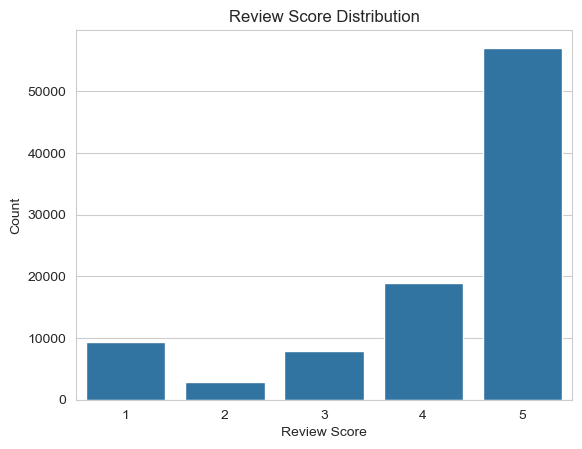

In [13]:
# Review score distribution 
sns.countplot(x="review_score", data=df)

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Count")

plt.show()

In [14]:
# Most customer gave high review scores, especially score 5,
# while lower ratings appear less frequently, suggesting that customer experiences were generally positive.

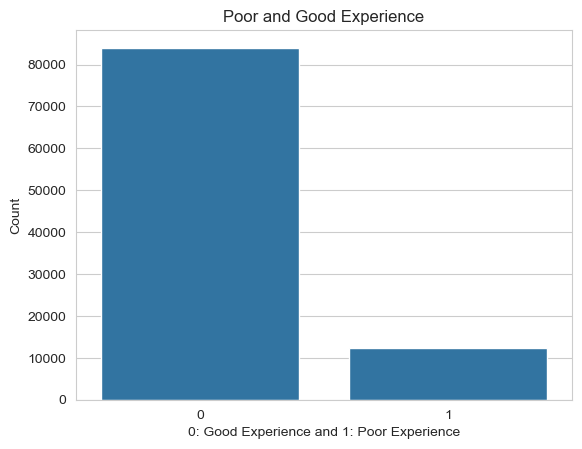

In [15]:
# Poor and good experience 
sns.countplot(x="poor_experience", data=df)

plt.title("Poor and Good Experience")
plt.xlabel("0: Good Experience and 1: Poor Experience")
plt.ylabel("Count")

plt.show()

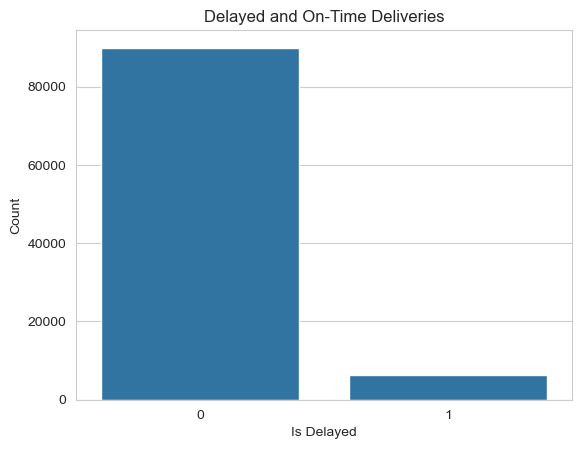

In [16]:
# Delayed and on-time deliveries 
sns.countplot(x="is_delayed", data=df)

plt.title("Delayed and On-Time Deliveries")
plt.xlabel("Is Delayed")
plt.ylabel("Count")

plt.show()


In [17]:
# Most orders were delivered on time

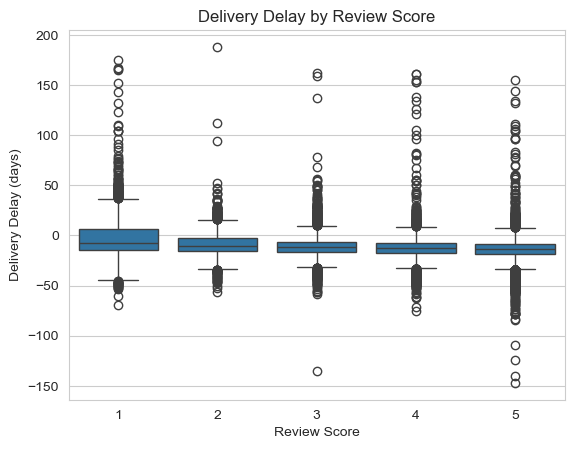

In [18]:
# Delivery delay and review score 
sns.boxplot(x="review_score", y="delivery_delay", data=df)

plt.title("Delivery Delay by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Delivery Delay (days)")

plt.show()


In [19]:
# Orders with lower review scores tend to have higher delivery delays

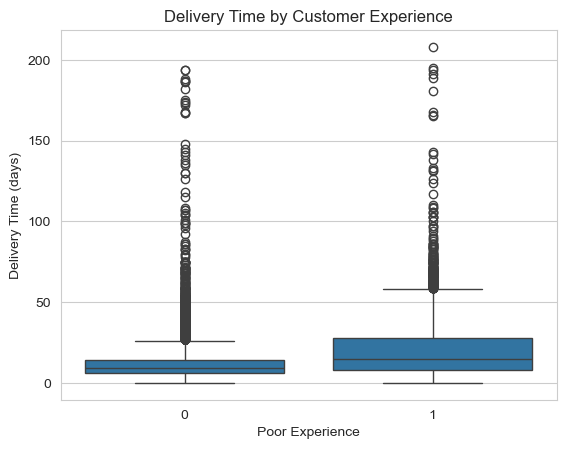

In [20]:
# Delivery time and customer experience 
sns.boxplot(x="poor_experience", y="delivery_time", data=df)

plt.title("Delivery Time by Customer Experience")
plt.xlabel("Poor Experience")
plt.ylabel("Delivery Time (days)")

plt.show()

In [21]:
# Poor customer experience tend to habe longer delivery times
# and greater variability compared to good experiences 

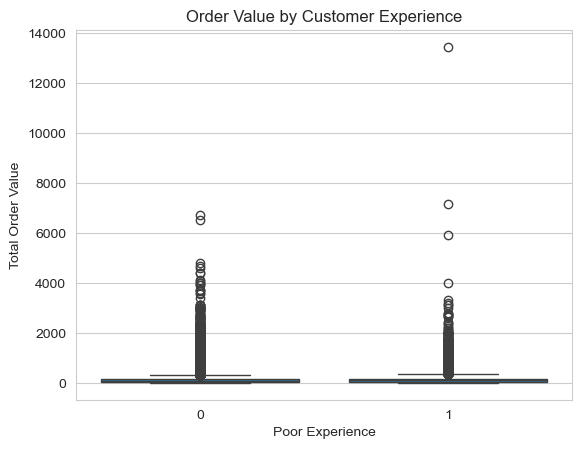

In [22]:
# Order value and customer experience
sns.boxplot(x="poor_experience", y="total_order_value", data=df)

plt.title("Order Value by Customer Experience")
plt.xlabel("Poor Experience")
plt.ylabel("Total Order Value")

plt.show()

In [23]:
# Order value shows a similar distribution across both groups, 
# suggesting a weaker relationship with customer experience 

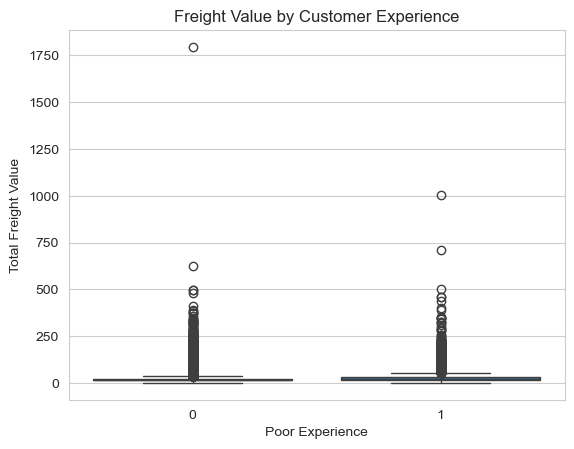

In [24]:
# Freight value and customer experience
sns.boxplot(x="poor_experience", y="total_freight_value", data=df)

plt.title("Freight Value by Customer Experience")
plt.xlabel("Poor Experience")
plt.ylabel("Total Freight Value")

plt.show()

In [25]:
# Freight values appear relatively similar between both groups,
# with only small differences in distribution 

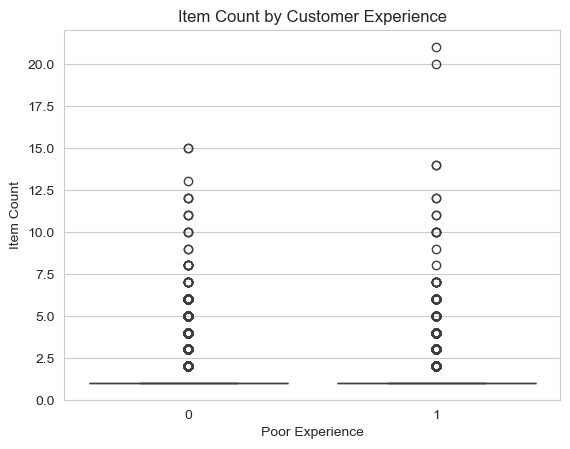

In [26]:
# Item count and customer experience
sns.boxplot(x="poor_experience", y="item_count", data=df)

plt.title("Item Count by Customer Experience")
plt.xlabel("Poor Experience")
plt.ylabel("Item Count")

plt.show()

In [27]:
# Item count appears similar across both groups, 
# suggesting weaker relationship with customer experience 

In [28]:
# Correlation matrix 
correlation = df[[
    "delivery_time",
    "delivery_delay",
    "total_order_value",
    "total_freight_value",
    "item_count",
    "review_score",
    "poor_experience"
]].corr()

print(correlation)

                     delivery_time  delivery_delay  total_order_value  \
delivery_time             1.000000        0.601746           0.055057   
delivery_delay            0.601746        1.000000          -0.014651   
total_order_value         0.055057       -0.014651           1.000000   
total_freight_value       0.167160       -0.050456           0.410038   
item_count               -0.019932       -0.032218           0.153561   
review_score             -0.333616       -0.267027          -0.034742   
poor_experience           0.311243        0.256886           0.042858   

                     total_freight_value  item_count  review_score  \
delivery_time                   0.167160   -0.019932     -0.333616   
delivery_delay                 -0.050456   -0.032218     -0.267027   
total_order_value               0.410038    0.153561     -0.034742   
total_freight_value             1.000000    0.438307     -0.090013   
item_count                      0.438307    1.000000     -0.12349

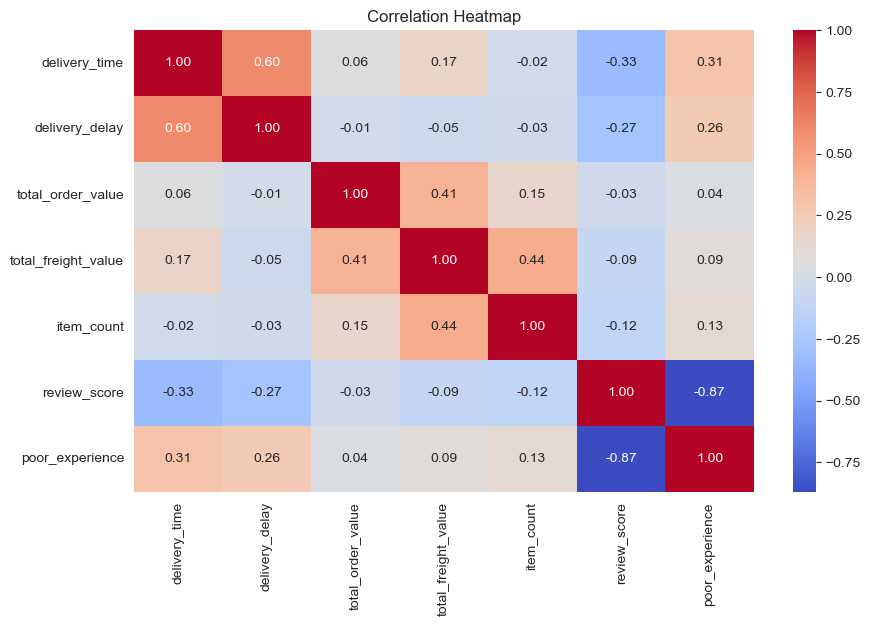

In [29]:
# Correlation heatmap 
plt.figure(figsize=(10,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [30]:
# Delivery-related variables show stronger correlation with customer experience, 
# while order characteristics present weaker relationships 

### 10. Prepare Data for Machine Learning 

In [31]:
# Predictor variables 
X = df[[
    "delivery_time",
    "delivery_delay",
    "total_order_value",
    "total_freight_value",
    "item_count"
]]

# Target variable 
y = df["poor_experience"]

In [32]:
# Split train and test datasets 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify shapes 
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(77082, 5)
(19271, 5)
(77082,)
(19271,)


In [33]:
# The dataset was split into training and testing sets while preserving the class distribuition 

### 11. Logistic Regression Model

In [34]:
from sklearn.linear_model import LogisticRegression

# Create model 
log_model = LogisticRegression(class_weight="balanced")

# Train model 
log_model.fit(X_train, y_train)

# Predictions 
y_pred = log_model.predict(X_test)

# Prediction probabilities 
y_prob = log_model.predict_proba(X_test)[:, 1]

### 12. Evaluate Logistic Regression 

In [35]:
from sklearn.metrics import( 
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [36]:
# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7532042966114888


In [37]:
# Precision
print("Precision:", precision_score(y_test, y_pred))

Precision: 0.2779180423383181


In [38]:
# Recall
print("Recall:", recall_score(y_test, y_pred))

Recall: 0.5795868772782503


In [39]:
# ROC-AUC
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.731690917622538


In [40]:
# Confusion matrix 
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[13084  3718]
 [ 1038  1431]]


In [41]:
# Classification report 
print("classification Report:")
print(classification_report(y_test, y_pred))

classification Report:
              precision    recall  f1-score   support

           0       0.93      0.78      0.85     16802
           1       0.28      0.58      0.38      2469

    accuracy                           0.75     19271
   macro avg       0.60      0.68      0.61     19271
weighted avg       0.84      0.75      0.79     19271



### 13. Random Forest Model

In [42]:
from sklearn.ensemble import RandomForestClassifier

# Create model 
rf_model = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

# Train model 
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)

# Predictions probabilities 
rf_prob = rf_model.predict_proba(X_test)[:,1]

### 14. Evaluate Random Forest 

In [43]:
# Accuracy
print("Accuracy:", accuracy_score(y_test, rf_pred))

Accuracy: 0.886980436925951


In [44]:
# Precision
print("Precision:", precision_score(y_test, rf_pred))

Precision: 0.6331198536139067


In [45]:
# Recall
print("Recall:", recall_score(y_test, rf_pred))

Recall: 0.2802754151478331


In [46]:
# ROC-AUC
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

ROC-AUC: 0.721902995790825


In [47]:
# Confusion matrix 
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Confusion Matrix:
[[16401   401]
 [ 1777   692]]


In [48]:
# Classification report 
print("classification Report:")
print(classification_report(y_test, rf_pred))

classification Report:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94     16802
           1       0.63      0.28      0.39      2469

    accuracy                           0.89     19271
   macro avg       0.77      0.63      0.66     19271
weighted avg       0.87      0.89      0.87     19271



### 15. Model Comparison

In [49]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ], 
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ], 
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

print(comparison)

                 Model  Accuracy  Precision    Recall   ROC-AUC
0  Logistic Regression  0.753204   0.277918  0.579587  0.731691
1        Random Forest  0.886980   0.633120  0.280275  0.721903


In [50]:
# Logistic Regression achieved better recall and ROC-AUC, while
# Random Forest showed higher accuracy and precision

### 16. Conclusions 

##### 
<br> This project explored the factors related to poor customer experience in e-commerce orders using the Olist Dataset. The results showed that delivery performance had the strongest relationship with customer satisfaction. 
<br> Orders with longer delivery times and lorger delay were more likely to receive lower review scores. 
In comparison, variables such as order value, freight value, and item count showed weaker relationships with customer experience.
<br> The analysis also showed that most orders arrived before the estimated delivery date, with an average of 12 days,  suggesting that the company may use conservative delivery estimates to avoid customer dissatisfaction. 
<br> The machine learning models supported these findings. Logistic Regression performed better at identifying poor customer experiences, while Random Forest achieved higher overall accuracy. 
<br> The result suggest that improving delivery performance may help reduce negative reviews and improve customer satisfaction. 